In [12]:

import sys
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay)

sys.path.insert(0, str(Path.cwd()))
from simple_cnn import build_simple_cnn

In [13]:

train_df = pd.read_csv("../data/train_split.csv")
val_df = pd.read_csv("../data/validation_split.csv")
test_df = pd.read_csv("../data/test_split.csv")

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 7000
Validation: 1500
Test: 1500


In [14]:

def load_image(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])
    image = tf.image.resize(image, (160, 160))
    image = tf.cast(image, tf.float32) / 255.0

    return image, tf.cast(label, tf.float32)


def create_dataset(df, shuffle=False):
    paths = [
        str((Path("../data") / name).resolve())
        for name in df["file_name"]
    ]
    labels = df["label"].to_numpy(dtype="float32")

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if shuffle:
        dataset = dataset.shuffle(1000, seed=42)

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return dataset.batch(16).prefetch(tf.data.AUTOTUNE)


train_ds = create_dataset(train_df, shuffle=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

In [15]:

model = build_simple_cnn()
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 160, 160, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 80, 80, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 40, 40, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,889 (429.25 KB)

 Trainable params: 109,889 (429.25 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_auc",
    mode="max",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stop]
)

Epoch 1/10


c:\project1\DNN-G5-AI-Generated-Image-Detection-Using-Deep-Neural-Networks\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


438/438 ━━━━━━━━━━━━━━━━━━━━ 71s 158ms/step - accuracy: 0.8101 - auc: 0.8928 - loss: 0.4216 - precision: 0.7990 - recall: 0.8289 - val_accuracy: 0.8787 - val_auc: 0.9545 - val_loss: 0.3000 - val_precision: 0.9494 - val_recall: 0.8000
Epoch 2/10
438/438 ━━━━━━━━━━━━━━━━━━━━ 65s 149ms/step - accuracy: 0.8776 - auc: 0.9424 - loss: 0.3108 - precision: 0.8762 - recall: 0.8794 - val_accuracy: 0.8900 - val_auc: 0.9560 - val_loss: 0.2983 - val_precision: 0.9295 - val_recall: 0.8440
Epoch 3/10
438/438 ━━━━━━━━━━━━━━━━━━━━ 70s 159ms/step - accuracy: 0.8870 - auc: 0.9494 - loss: 0.2891 - precision: 0.8812 - recall: 0.8946 - val_accuracy: 0.8993 - val_auc: 0.9586 - val_loss: 0.2585 - val_precision: 0.9009 - val_recall: 0.8973
Epoch 4/10
438/438 ━━━━━━━━━━━━━━━━━━━━ 70s 159ms/step - accuracy: 0.8951 - auc: 0.9541 - loss: 0.2743 - precision: 0.8885 - recall: 0.9037 - val_accuracy: 0.9073 - val_auc: 0.9648 - val_loss: 0.2446 - val_precision: 0.9371 - val_recall: 0.8733
Epoch 5/10
438/438 ━━━━━━━━━━━━

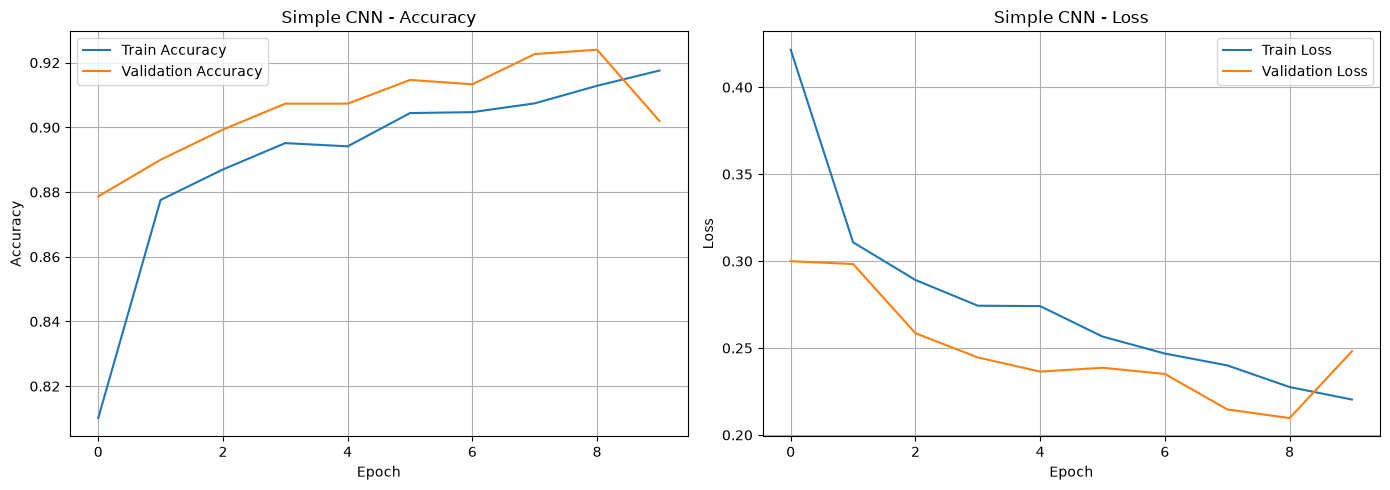

In [17]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history["accuracy"], label="Train Accuracy")
axes[0].plot(history.history["val_accuracy"], label="Validation Accuracy")
axes[0].set_title("Simple CNN - Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history.history["loss"], label="Train Loss")
axes[1].plot(history.history["val_loss"], label="Validation Loss")
axes[1].set_title("Simple CNN - Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [18]:

y_true = test_df["label"].to_numpy(dtype=int)

y_prob = model.predict(test_ds).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("Accuracy :", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred, zero_division=0))
print("Recall   :", recall_score(y_true, y_pred, zero_division=0))
print("F1-score :", f1_score(y_true, y_pred, zero_division=0))

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["Real image", "AI-generated image"],
        zero_division=0
    )
)

94/94 ━━━━━━━━━━━━━━━━━━━━ 14s 148ms/step
Accuracy : 0.9106666666666666
Precision: 0.9
Recall   : 0.924
F1-score : 0.9118421052631579

Classification Report:
                    precision    recall  f1-score   support

        Real image       0.92      0.90      0.91       750
AI-generated image       0.90      0.92      0.91       750

          accuracy                           0.91      1500
         macro avg       0.91      0.91      0.91      1500
      weighted avg       0.91      0.91      0.91      1500



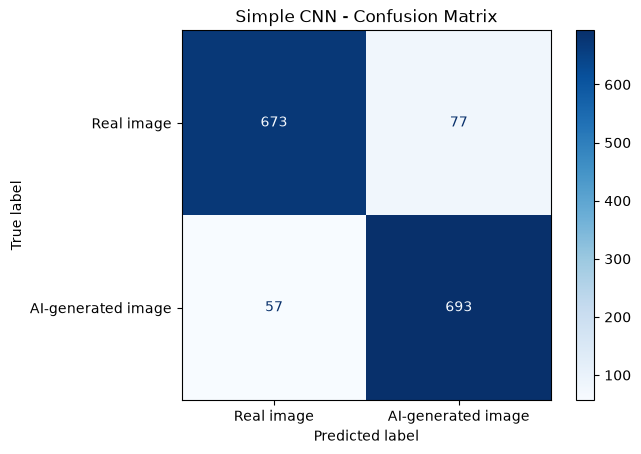

In [19]:

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Real image", "AI-generated image"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("Simple CNN - Confusion Matrix")
plt.show()

In [20]:

Path("../results/models").mkdir(parents=True, exist_ok=True)
Path("../results/metrics").mkdir(parents=True, exist_ok=True)
Path("../results/figures").mkdir(parents=True, exist_ok=True)

model.save("../results/models/simple_cnn.keras")

metrics = {
    "accuracy": accuracy_score(y_true, y_pred),
    "precision": precision_score(y_true, y_pred, zero_division=0),
    "recall": recall_score(y_true, y_pred, zero_division=0),
    "f1_score": f1_score(y_true, y_pred, zero_division=0)
}

pd.DataFrame([metrics]).to_csv(
    "../results/metrics/simple_cnn_metrics.csv",
    index=False
)

fig.savefig("../results/figures/simple_cnn_metrics.png", dpi=150)

print("Đã lưu mô hình và các chỉ số.")

Đã lưu mô hình và các chỉ số.
